## Predict the diffusivity w.r.t Density and Temperature, $D(\rho^*,T^*)$

In [40]:
import numpy as np
import torch
from torch import nn
import torchvision
import matplotlib.pyplot as plt
%matplotlib inline
from torch.utils.tensorboard import SummaryWriter
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset
import datetime
import random

In [2]:
diff_arr = np.loadtxt('diff2darr.txt')

In [28]:
print(diff_arr[1])

[0.2        0.05       0.02585112]


In [ ]:
T = diff_T[:,0]
D_0 = 0.5*diff_T[:,2]
T_trch = torch.from_numpy(T)
D_true = torch.from_numpy(D_0)

In [42]:
indices = range(0,240)
rand_indices = random.sample(indices, 160)

print(rand_indices)
training_set = []
testing_set = []
for i in range(240):
    #print(i)
    if i in rand_indices:
        training_set.append(diff_arr[i])
    else:
        testing_set.append(diff_arr[i])

[13, 211, 176, 144, 79, 199, 217, 230, 186, 92, 130, 200, 145, 160, 53, 141, 125, 40, 94, 74, 215, 16, 157, 139, 8, 111, 159, 194, 162, 30, 66, 37, 238, 226, 147, 62, 221, 180, 73, 192, 96, 83, 35, 80, 103, 36, 67, 237, 15, 52, 185, 6, 228, 77, 33, 220, 142, 115, 224, 208, 87, 179, 18, 31, 135, 70, 205, 2, 60, 21, 61, 47, 76, 11, 203, 156, 189, 41, 131, 43, 181, 196, 69, 169, 1, 65, 127, 161, 118, 27, 75, 132, 222, 178, 29, 140, 150, 42, 126, 109, 209, 148, 235, 168, 191, 25, 5, 98, 146, 58, 54, 122, 227, 45, 116, 214, 195, 20, 114, 216, 166, 88, 0, 84, 170, 44, 213, 124, 154, 210, 22, 117, 28, 167, 119, 187, 3, 174, 151, 105, 51, 90, 55, 89, 38, 120, 173, 239, 206, 107, 152, 143, 14, 23, 110, 212, 136, 188, 108, 113]


In [48]:
training_set = np.array(training_set)
T_train_np = training_set[:,0]
rho_train_np = training_set[:,1]
D_train_np = training_set[:,2]

testing_set = np.array(testing_set)
T_test_np = testing_set[:,0]
rho_test_np = testing_set[:,1]
D_test_np = testing_set[:,2]


In [53]:
T_train = torch.from_numpy(T_train_np)
rho_train = torch.from_numpy(rho_train_np)
D_train = torch.from_numpy(D_train_np)

T_test = torch.from_numpy(T_test_np)
rho_test = torch.from_numpy(rho_test_np)
D_test = torch.from_numpy(D_test_np)


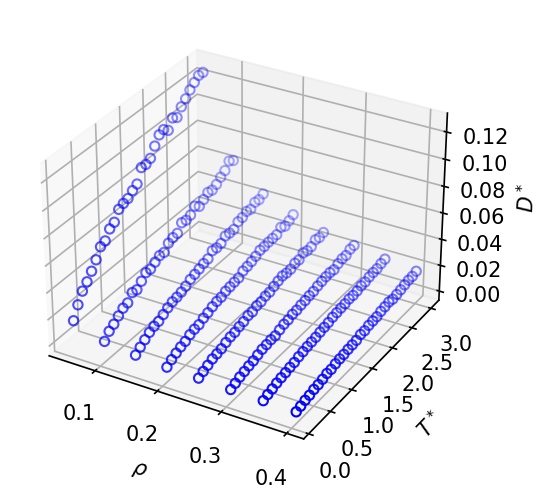

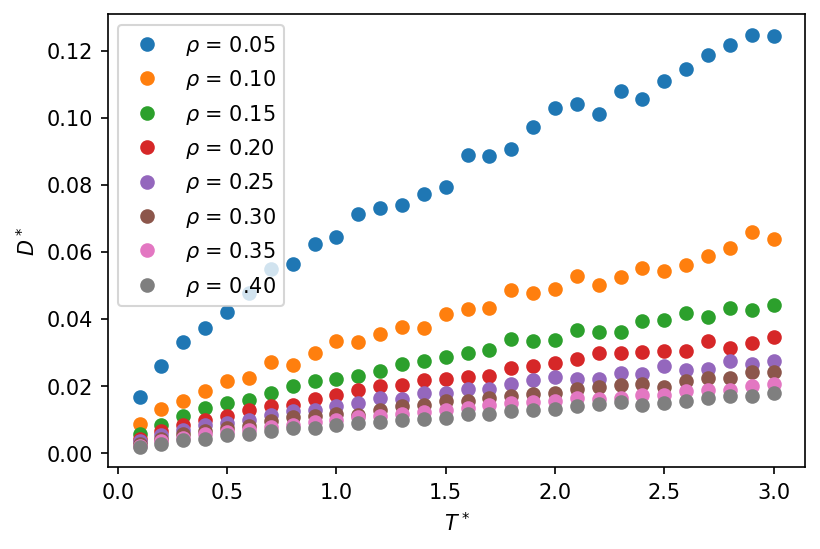

In [91]:
fig_id = 1
plt.rcParams['figure.dpi'] = 150 
fig = plt.figure(fig_id)

ax = fig.add_subplot(111, projection='3d')
ax.scatter(diff_arr[:,1], diff_arr[:,0], diff_arr[:,2],facecolors='none', edgecolors='b')
ax.set_xlabel(r"$\rho$")
ax.set_ylabel('$T^*$')
ax.set_zlabel('$D^*$')
plt.show()
fig_id += 1

diff_spl = np.split(diff_arr,8)
plt.rcParams['figure.dpi'] = 150 
fig = plt.figure(fig_id)

for r in range(len(diff_spl)):
    diff_r = diff_spl[r]
    
    labelr =  r"$\rho$ = "+ str(format(diff_r[0,1], '.2f'))
    plt.plot(diff_r[:,0], diff_r[:,2], 'o',label = labelr)
    
plt.xlabel('$T^*$')
plt.ylabel('$D^*$')
plt.legend()
plt.show()
fig_id += 1

In [55]:
class ffnn(nn.Module):
    """basic FF network for approximating functions"""
    def __init__(self, nn_width=10, num_hidden=1):
        super().__init__()
        
        self.layer_first = nn.Linear(2, nn_width)
        
        layers = []
        for _ in range(num_hidden):
            layers.append(nn.Linear(nn_width, nn_width))
        self.layer_hidden = nn.ModuleList(layers)
        
        self.layer_last = nn.Linear(nn_width, 1)
        
    def forward(self, x, y):
        xy = torch.cat((x, y), -1)
        activation = nn.Tanh()
        u = activation(self.layer_first(xy))
        for hidden in self.layer_hidden:
            u = activation(hidden(u))
        u = self.layer_last(u)
        return u

In [56]:
def loss_train(model,T, rho):

    d_p = model(T.float(),rho.float())
    loss = torch.pow(D_train - d_p, 2).mean()
    return 1000*loss

def loss_test(model, rho, T):
    d_p = model(T.float(),rho.float())
    loss = torch.pow(D_test - d_p, 2).mean()
    return 1000*loss

In [72]:
model = ffnn()
lr = 0.01
n_epochs = 20000
opt = torch.optim.Adam(model.parameters(), lr)
loss_train_hist = []
loss_test_hist = []
T_train = T_train.reshape(len(T_train),1)
rho_train = rho_train.reshape(len(rho_train),1)
D_train = D_train.reshape(len(D_train),1)
T_test = T_test.reshape(len(T_test),1)
rho_test = rho_test.reshape(len(rho_test),1)
D_test = D_test.reshape(len(D_test),1)

In [73]:
print(T_train.shape)
print(len(rho_train))

torch.Size([160, 1])
160


In [74]:
for i in range(n_epochs):
    loss_i = loss_train(model, T_train, rho_train)
    loss_test_i = loss_test(model,T_test, rho_test)
    opt.zero_grad()
    loss_train_hist.append(loss_i.item())
    loss_test_hist.append(loss_test_i.item())
    loss_i.backward()
    opt.step()
    
    if i % 100 == 0 or i == n_epochs-1:
        print(f'epoch {i}, loss = {loss_i}, loss_test = {loss_test_i}')

epoch 0, loss = 182.8214531251055, loss_test = 157.43783380036598
epoch 100, loss = 0.6666807719423369, loss_test = 0.5726746923735272
epoch 200, loss = 0.2916393978388144, loss_test = 15.6130201283896
epoch 300, loss = 0.22179056870067407, loss_test = 28.42246344579357
epoch 400, loss = 0.20549297570834857, loss_test = 26.306597269566716
epoch 500, loss = 0.1931056434283087, loss_test = 23.15145591217997
epoch 600, loss = 0.18284092853062878, loss_test = 19.45452615388125
epoch 700, loss = 0.17411791644211183, loss_test = 15.160093563858412
epoch 800, loss = 0.16657126026112326, loss_test = 10.493648407657405
epoch 900, loss = 0.15975277117600542, loss_test = 6.204748113130781
epoch 1000, loss = 0.15295994219332995, loss_test = 3.093270413612265
epoch 1100, loss = 0.14526206354809026, loss_test = 1.341816331838132
epoch 1200, loss = 0.13564030271551125, loss_test = 0.6348869581913735
epoch 1300, loss = 0.12284380924585328, loss_test = 0.5849282289755365
epoch 1400, loss = 0.1050233567

epoch 11500, loss = 0.0013449638875361752, loss_test = 2.7907180416518504
epoch 11600, loss = 0.0013466422485946036, loss_test = 2.7616018789258105
epoch 11700, loss = 0.0013240136002634429, loss_test = 2.7345112318332454
epoch 11800, loss = 0.0014194582572163853, loss_test = 2.735143517664911
epoch 11900, loss = 0.001307447423847226, loss_test = 2.650210788688309
epoch 12000, loss = 0.0013638365188554037, loss_test = 2.635221126419262
epoch 12100, loss = 0.0012923225101952546, loss_test = 2.5845654982084874
epoch 12200, loss = 0.0014013701438686718, loss_test = 2.571302686175292
epoch 12300, loss = 0.0012800426743033607, loss_test = 2.5256295025159115
epoch 12400, loss = 0.012821921396784983, loss_test = 2.5122778050149868
epoch 12500, loss = 0.0012673582219854735, loss_test = 2.4559344601035167
epoch 12600, loss = 0.0015199532952615414, loss_test = 2.414939856159236
epoch 12700, loss = 0.0012525448462391104, loss_test = 2.380053172452482
epoch 12800, loss = 0.0012577008505705667, los

In [76]:
d_p_train = model(T_train.float(),rho_train.float())
d_p_test = model(T_test.float(), rho_test.float())


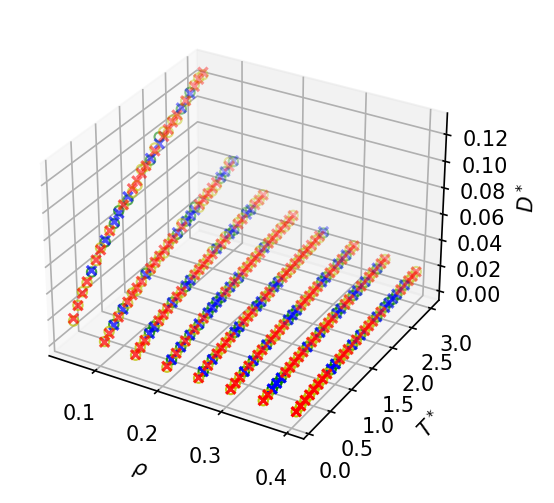

In [77]:
plt.rcParams['figure.dpi'] = 150 
fig = plt.figure(fig_id)

ax = fig.add_subplot(111, projection='3d')
ax.scatter(rho_train_np, T_train_np, D_train_np, facecolors='none', edgecolors='y',label = 'Training Data')
ax.scatter(rho_train_np, T_train_np, d_p_train.detach().numpy() ,marker='x',c='r', label="Training Prediction")
ax.scatter(rho_test_np, T_test_np, D_test_np, facecolors='none', edgecolors='g',label = 'Testing Data')
ax.scatter(rho_test_np, T_test_np, d_p_test.detach().numpy() ,marker='x',c='b', label="Training Prediction")
ax.set_xlabel(r"$\rho$")
ax.set_ylabel('$T^*$')
ax.set_zlabel('$D^*$')
plt.show()
fig_id += 1

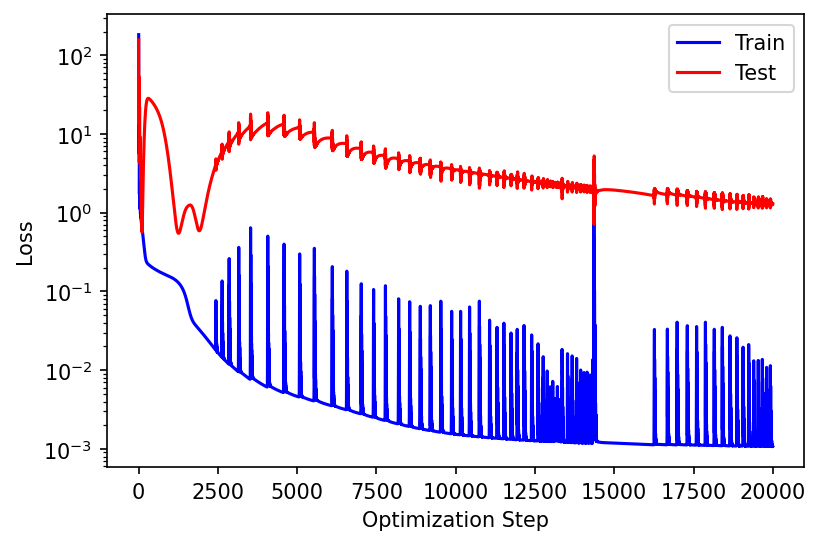

In [94]:
plt.rcParams['figure.dpi'] = 150 
fig = plt.figure(fig_id)

plt.semilogy(loss_train_hist,'b',label = 'Train')
plt.semilogy(loss_test_hist,'r',label = 'Test')
plt.xlabel('Optimization Step')
plt.ylabel('Loss')
plt.legend()
fig_id += 1

In [82]:
print(diff_spl[0][:,0])
print(diff_spl[0][0,1])
print(diff_spl[0][:,2])

[0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1.  1.1 1.2 1.3 1.4 1.5 1.6 1.7 1.8
 1.9 2.  2.1 2.2 2.3 2.4 2.5 2.6 2.7 2.8 2.9 3. ]
0.05
[0.01685227 0.02585112 0.03316556 0.03719872 0.04220378 0.04787766
 0.05477614 0.0562865  0.0624191  0.06459919 0.07145265 0.07312223
 0.07405266 0.07722381 0.07942668 0.08904729 0.08876101 0.090617
 0.09716024 0.10291303 0.10424869 0.10113626 0.10787938 0.10570074
 0.11113107 0.11461695 0.11874133 0.12187622 0.12470614 0.12454975]
